# Import Library dan Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules


In [2]:
df=pd.read_csv("Groceries_dataset.csv")
df.head(5)

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk


# Pengecekan Tipe Data dan Missing Value

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Member_number    38765 non-null  int64
 1   Date             38765 non-null  str  
 2   itemDescription  38765 non-null  str  
dtypes: int64(1), str(2)
memory usage: 1.6 MB


# Penanganan Tipe Data

In [4]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Member_number    38765 non-null  int64         
 1   Date             38765 non-null  datetime64[us]
 2   itemDescription  38765 non-null  str           
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 1.3 MB


# Pengecekan Statistik Deskriptif

In [5]:
df.describe(include='all')

,Member_number,Date,itemDescription
count,38765.000000,38765,38765
unique,NaN,NaN,167
top,NaN,NaN,whole milk
freq,NaN,NaN,2502
mean,3003.641868,2015-01-09 18:17:12.498387,NaN
min,1000.000000,2014-01-01 00:00:00,NaN
25%,2002.000000,2014-07-12 00:00:00,NaN
50%,3005.000000,2015-01-21 00:00:00,NaN
75%,4007.000000,2015-07-10 00:00:00,NaN
max,5000.000000,2015-12-30 00:00:00,NaN


# Pengecekan Duplikat

In [6]:
df[df.duplicated()]

,Member_number,Date,itemDescription
5015,2051,2015-09-11,frankfurter
5022,3055,2015-08-18,other vegetables
5044,1994,2015-03-11,whole milk
5055,1682,2015-06-25,pip fruit
5059,4324,2015-01-05,sausage
...,...,...,...
38614,2027,2014-02-26,domestic eggs
38684,2936,2014-03-07,newspapers
38685,2311,2014-03-13,pot plants
38722,3834,2014-05-18,salty snack


# Penanganan Duplikat

In [7]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

# Pengecekan Konsistensi

In [8]:
pd.set_option('display.max_rows', None)
df["itemDescription"].value_counts().sort_index(ascending=True)

itemDescription
Instant food products          60
UHT-milk                      320
abrasive cleaner               22
artif. sweetener               29
baby cosmetics                  3
bags                            4
baking powder                 121
bathroom cleaner               17
beef                          508
berries                       326
beverages                     248
bottled beer                  678
bottled water                 908
brandy                         38
brown bread                   563
butter                        527
butter milk                   263
cake bar                       92
candles                        66
candy                         215
canned beer                   702
canned fish                   115
canned fruit                   21
canned vegetables              82
cat food                      177
cereals                        42
chewing gum                   180
chicken                       417
chocolate                     35

In [9]:
pd.reset_option('display.max_rows')  #mereset kembali option 'display.max_rows'

# Pengecekan Spasi Berlebih pada kolom itemDescription

In [10]:
# Mengecek spasi di awal/akhir nama produk
df['itemDescription'].str.strip().ne(
    df['itemDescription']
).sum()

np.int64(436)

In [11]:
df['itemDescription']=df['itemDescription'].str.strip() #menghapus spasi berlebih

# Outlier

C:\Users\ASUS\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


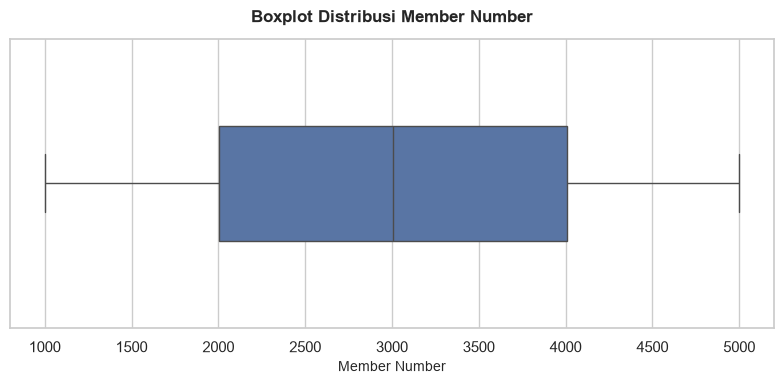

In [12]:
plt.figure(figsize=(8, 4))
sns.set_theme(style="whitegrid")
    
sns.boxplot(x=df['Member_number'], color='#4C72B0', width=0.4)

plt.title('Boxplot Distribusi Member Number', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Member Number', fontsize=10)
plt.tight_layout()
plt.show()

# Feature Engineering

## Membuat Transaction ID

In [13]:
df['Transaction_ID'] = df['Member_number'].astype(str) + '_' + df['Date'].dt.strftime('%d-%m-%Y')
df.head(5)

,Member_number,Date,itemDescription,Transaction_ID
0,1808,2015-07-21,tropical fruit,1808_21-07-2015
1,2552,2015-01-05,whole milk,2552_05-01-2015
2,2300,2015-09-19,pip fruit,2300_19-09-2015
3,1187,2015-12-12,other vegetables,1187_12-12-2015
4,3037,2015-02-01,whole milk,3037_01-02-2015


# EDA

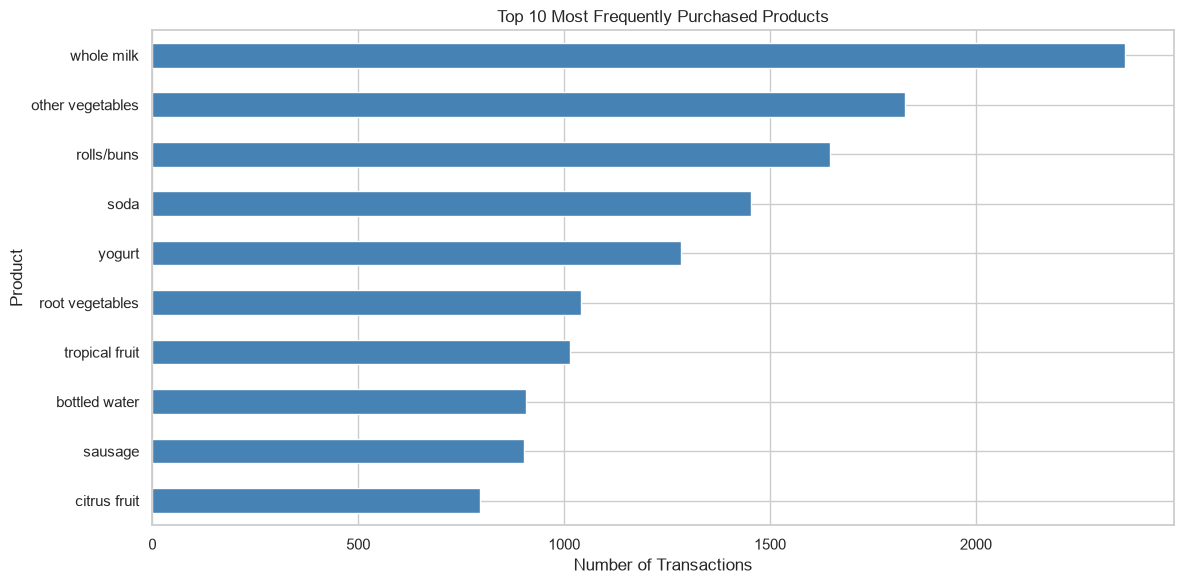

In [14]:
top_10 = (
    df['itemDescription']
    .value_counts()
    .head(10)
)

plt.figure(figsize=(12, 6))

top_10.sort_values().plot(
    kind='barh',
    color='steelblue'
)

plt.title('Top 10 Most Frequently Purchased Products')
plt.xlabel('Number of Transactions')
plt.ylabel('Product')
plt.tight_layout()
plt.show()

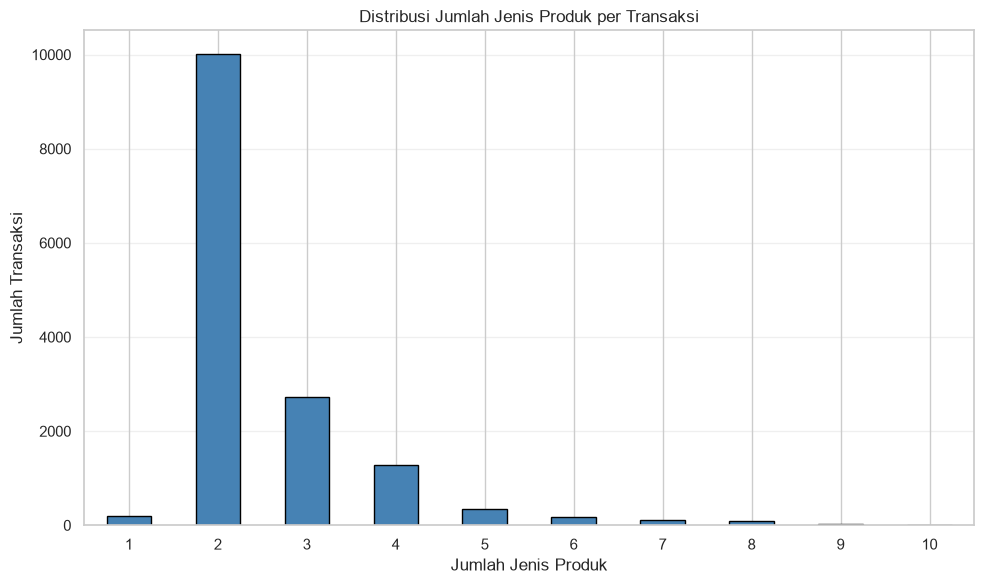

In [15]:
basket_size = (
    df.groupby(['Member_number', 'Date'])['itemDescription']
    .nunique()
    .reset_index(name='Jumlah_Produk')
)

basket_distribution = (
    basket_size['Jumlah_Produk']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

basket_distribution.plot(
    kind='bar',
    color='steelblue',
    edgecolor='black'
)

plt.title('Distribusi Jumlah Jenis Produk per Transaksi')
plt.xlabel('Jumlah Jenis Produk')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

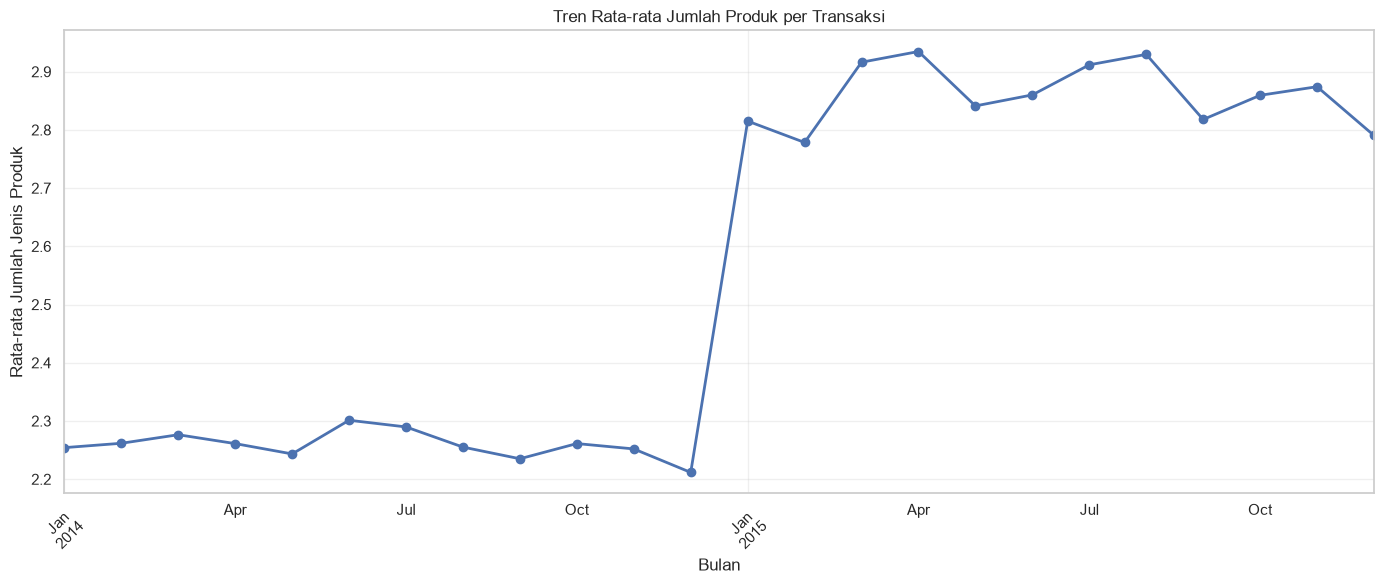

In [16]:
# Membuat kolom bulan
basket_size['Month'] = basket_size['Date'].dt.to_period('M')

# Rata-rata jumlah produk per transaksi setiap bulan
monthly_trend = (
    basket_size.groupby('Month')['Jumlah_Produk']
    .mean()
)

# Visualisasi
plt.figure(figsize=(14, 6))

monthly_trend.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title('Tren Rata-rata Jumlah Produk per Transaksi')
plt.xlabel('Bulan')
plt.ylabel('Rata-rata Jumlah Jenis Produk')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Apriori 

In [17]:
basket = pd.crosstab(
    df['Transaction_ID'],
    df['itemDescription']
).gt(0)
basket.head()

itemDescription,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
Transaction_ID,,,,,,,,,,,,,,,,,,,,,
1000_15-03-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1000_24-06-2014,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1000_24-07-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1000_25-11-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1000_27-05-2015,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [18]:
frequent_itemsets = apriori(
    basket,
    min_support=0.002,
    use_colnames=True
)
frequent_itemsets.sort_values(
    by='support',
    ascending=False
)

,support,itemsets
123,0.157923,frozenset({whole milk})
78,0.122101,frozenset({other vegetables})
93,0.110005,frozenset({rolls/buns})
104,0.097106,frozenset({soda})
124,0.085879,frozenset({yogurt})
...,...,...
213,0.002005,"frozenset({root vegetables, domestic eggs})"
229,0.002005,"frozenset({frozen vegetables, soda})"
196,0.002005,"frozenset({coffee, root vegetables})"
252,0.002005,"frozenset({newspapers, pastry})"


## Association Rules

In [22]:
rules = association_rules(
    frequent_itemsets,
    metric='confidence',
    min_threshold=0.05
)
rules[
    ['antecedents', 'consequents',
     'support', 'confidence', 'lift']
].sort_values(
    by='lift',
    ascending=False
).head(10)

,antecedents,consequents,support,confidence,lift
75,frozenset({curd}),frozenset({sausage}),0.002941,0.087302,1.446615
30,frozenset({brown bread}),frozenset({canned beer}),0.002406,0.063943,1.362937
31,frozenset({canned beer}),frozenset({brown bread}),0.002406,0.051282,1.362937
99,frozenset({frozen vegetables}),frozenset({sausage}),0.002072,0.073986,1.225966
12,frozenset({sausage}),frozenset({bottled beer}),0.003342,0.055371,1.222000
11,frozenset({bottled beer}),frozenset({sausage}),0.003342,0.073746,1.222000
89,frozenset({frankfurter}),frozenset({other vegetables}),0.005146,0.136283,1.116150
195,frozenset({yogurt}),frozenset({sausage}),0.005748,0.066926,1.108986
194,frozenset({sausage}),frozenset({yogurt}),0.005748,0.095238,1.108986
98,frozenset({frozen vegetables}),frozenset({root vegetables}),0.002139,0.076372,1.097751


# Ekspor Data

## Dataset Utama

In [ ]:
df.to_csv(
    'clean_dat_MBA.csv',
    index=False
)

## Apriori

In [ ]:
# Salin hasil Apriori
apriori_export = frequent_itemsets.copy()

# Mengubah frozenset menjadi string
apriori_export['itemsets'] = (
    apriori_export['itemsets']
    .apply(lambda x: ', '.join(sorted(x)))
)

# Export CSV
apriori_export.to_csv(
    'apriori.csv',
    index=False
)

## Association Rules

In [ ]:
# Salin hasil association rules
association_export = rules.copy()

# Mengubah antecedents dan consequents menjadi teks
for col in ['antecedents', 'consequents']:
    association_export[col] = (
        association_export[col]
        .apply(lambda x: ', '.join(sorted(x)))
    )

# Export CSV
association_export.to_csv(
    'association.csv',
    index=False
)